# STATS 425 · Week 9 lab
**Embeddings and retrieval**  
**TA:** Ali Kaazempur-Mofrad

In Week 1, we used a language model's log-probabilities to score text. In Weeks 4–7, we trained small policies with rewards and preferences, and in Week 8, we measured a fixed model's uncertainty. Today, we turn to the **text-mining** side of the course: we represent documents as vectors, search for the documents closest to a question, group documents into topics without using their labels, and retrieve evidence to place in front of a question.

**How this connects to a language model.** A language model answers from two sources: what its weights store, and the text in its prompt. Retrieval adds relevant text to the prompt. In Section 5, we apply Week 1's scoring to check whether retrieved evidence raises DistilGPT2's probability of a correct answer.

| Section | Question we answer |
|---|---|
| 1. Documents as vectors | How can we turn a document into a vector of numbers? |
| 2. Similarity search | Which documents are closest to a question, and how do we measure retrieval quality? |
| 3. Topics from similarity | Can we recover the topics without using their labels? |
| 4. Retrieval before answering | How do we place retrieved evidence in a prompt? |
| 5. Scoring answers with DistilGPT2 | Does retrieved evidence raise the probability of a correct answer? |

**Set up the notebook.** Sections 1–4 run on a standard Google Colab runtime with no graphics processing unit (GPU) and no model download: the cell below imports scikit-learn, NumPy, and Matplotlib (all included in Colab), installs PyTorch only if it is missing, and sets a random seed so that the results are repeatable. Section 5 installs the Transformers versions from Weeks 1–3 and downloads DistilGPT2, as in those weeks.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2.8,<3"])

import math
import random

import matplotlib.pyplot as plt
import numpy as np
import sklearn
import torch
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import normalize

SEED = 425
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__} | Device: CPU")

PyTorch 2.8.0+cu128 | scikit-learn 1.9.1 | Device: CPU


## 1 · Documents as vectors

So far, our models have read text as token IDs (Weeks 1–3) or read numbers directly (Weeks 4–8). Many text-mining tasks start with a simpler question: **which documents are about the same thing?** To answer it with statistics, we first turn each document into a vector of numbers.

**Meet the corpus.** A collection of documents is called a **corpus**. Ours has 36 short documents, written for this lab, on four topics: kidney exchange, academic hiring, weather, and cooking. Each document has an ID (`K1`–`K9`, `J1`–`J9`, `W1`–`W9`, `C1`–`C9`) and a topic label. We use the labels only to check our results; none of the methods in Sections 1–3 sees them.

The cell below stores the corpus and prints one example per topic.

In [2]:
TOPICS = ("kidney exchange", "academic hiring", "weather", "cooking")

DOCUMENTS = [
    # (document ID, topic, text)
    ("K1", "kidney exchange",
     "A kidney exchange helps patients who have a willing living donor whose kidney is "
     "incompatible with them. Two incompatible patient-donor pairs can swap donors, so each "
     "patient receives a compatible kidney."),
    ("K2", "kidney exchange",
     "Whether a donor kidney is compatible with a patient depends on blood type and on "
     "antibodies in the patient's blood. A crossmatch test checks whether those antibodies "
     "would attack the donor kidney."),
    ("K3", "kidney exchange",
     "A patient with blood type O can usually receive a kidney only from a type O donor, so "
     "type O patients often wait longer for a compatible donor in a kidney exchange."),
    ("K4", "kidney exchange",
     "An altruistic donor gives a kidney without naming a patient. Such a donor can start a "
     "chain of kidney transplants, in which each patient's paired donor gives a kidney to the "
     "next patient in the chain."),
    ("K5", "kidney exchange",
     "In a two-way kidney swap, the four surgeries are usually scheduled on the same day, so no "
     "donor can back out after their own patient has received a kidney."),
    ("K6", "kidney exchange",
     "Larger kidney exchange pools find more transplants because each incompatible "
     "patient-donor pair has more potential partners. Many programs combine pairs from "
     "several transplant centers into one pool."),
    ("K7", "kidney exchange",
     "Kidneys from deceased donors are offered to patients on a waiting list, which ranks "
     "patients using factors such as time spent waiting and how hard each patient is to "
     "match with a donor."),
    ("K8", "kidney exchange",
     "Fairness is a central question in kidney allocation. A policy that maximizes the total "
     "number of transplants can still leave hard-to-match patients waiting much longer than "
     "other patients."),
    ("K9", "kidney exchange",
     "Matching algorithms for kidney exchange search the pool of incompatible patient-donor "
     "pairs for cycles and chains. Limiting the length of each cycle keeps the number of "
     "transplant surgeries that must happen together manageable."),
    ("J1", "academic hiring",
     "Each fall, university departments advertise faculty positions. Applicants submit a "
     "cover letter, a curriculum vitae, research and teaching statements, and reference "
     "letters to each department."),
    ("J2", "academic hiring",
     "A hiring committee reads the faculty applications and builds a short list of applicants "
     "to interview. Because the committee has limited time, many qualified applicants never "
     "receive an interview."),
    ("J3", "academic hiring",
     "Faculty job interviews often begin with a short video call, followed by a campus visit "
     "for a few finalists. A campus visit usually includes a research talk and meetings with "
     "faculty and students in the department."),
    ("J4", "academic hiring",
     "Some academic job markets let applicants send a small number of preference signals to "
     "show special interest in a faculty position. A signal helps a hiring committee identify "
     "applicants who are likely to accept a job offer."),
    ("J5", "academic hiring",
     "Interview congestion arises when many applicants apply to the same faculty positions and "
     "hiring committees cannot tell which applicants are seriously interested. Signals can "
     "spread interviews more evenly across applicants."),
    ("J6", "academic hiring",
     "After the campus visits, the department faculty vote and the department makes a job "
     "offer to its top applicant. The applicant may negotiate salary, start date, and research "
     "funding before accepting the offer."),
    ("J7", "academic hiring",
     "Faculty job offers often come with a deadline. An applicant holding one offer while "
     "waiting to hear from other departments must decide whether to accept early."),
    ("J8", "academic hiring",
     "Postdoctoral positions give recent graduates time to build a research record before "
     "they apply for faculty jobs in academic departments."),
    ("J9", "academic hiring",
     "A tenure-track assistant professor is reviewed for tenure by the department after "
     "several years, based on research, teaching, and service to the university."),
    ("W1", "weather",
     "Weather describes short-term conditions of the air, such as temperature, humidity, wind, "
     "and rain. Climate describes average weather conditions over many years."),
    ("W2", "weather",
     "Clouds form when rising air cools and water vapor in the air condenses into tiny "
     "droplets. The temperature at which water vapor begins to condense is called the dew "
     "point."),
    ("W3", "weather",
     "Relative humidity compares the water vapor in the air with the most water vapor the air "
     "could hold at its temperature. Warm air can hold more water vapor than cold air."),
    ("W4", "weather",
     "A cold front forms where cold air pushes under warm air. The warm air is forced upward, "
     "and the weather along the front often turns to showers or thunderstorms."),
    ("W5", "weather",
     "Air pressure is the weight of the air above a place. Falling air pressure often signals "
     "that stormy weather is approaching, while rising air pressure usually brings clear "
     "weather."),
    ("W6", "weather",
     "Weather forecasters run computer models of the air many times from slightly different "
     "starting conditions. The spread of these runs shows how uncertain the weather forecast "
     "is."),
    ("W7", "weather",
     "A weather forecast of a 30 percent chance of rain means that, over many days with the "
     "same forecast, rain should fall on about three days in ten."),
    ("W8", "weather",
     "Coastal towns often have milder weather than inland towns because the ocean warms and "
     "cools more slowly than land, which keeps the air temperature steadier."),
    ("W9", "weather",
     "Thunderstorms need moist air, unstable air, and something that lifts the air, such as a "
     "cold front or an area of low air pressure."),
    ("C1", "cooking",
     "Searing meat in a very hot pan browns its surface through the Maillard reaction, a set "
     "of reactions between amino acids and sugars that gives cooked food new flavors."),
    ("C2", "cooking",
     "Bread dough rises because yeast in the dough ferments sugars and releases carbon "
     "dioxide gas, which is trapped by a network of gluten proteins."),
    ("C3", "cooking",
     "Kneading bread dough develops gluten, which makes the dough stretchy and helps the "
     "bread hold its shape as it rises and bakes."),
    ("C4", "cooking",
     "Salt does more than add flavor to food: in bread dough it strengthens gluten, and on "
     "vegetables it draws out moisture before cooking."),
    ("C5", "cooking",
     "At high altitude, water boils at a lower temperature because of the lower air pressure, "
     "so pasta and beans take longer to cook in the mountains."),
    ("C6", "cooking",
     "Braising cooks tough cuts of meat slowly in a little liquid in a covered pot, which "
     "turns connective tissue into gelatin and makes the meat tender."),
    ("C7", "cooking",
     "Baking soda releases carbon dioxide when it reacts with an acid such as buttermilk or "
     "lemon juice, which makes pancakes and quick bread rise as they cook."),
    ("C8", "cooking",
     "Recipes written for sea level often need changes for cooking and baking in the "
     "mountains, where cakes can rise too fast and liquids evaporate faster."),
    ("C9", "cooking",
     "Mayonnaise is an emulsion: egg yolk helps tiny droplets of oil stay mixed with lemon "
     "juice or vinegar instead of separating, so no cooking is needed."),
]

doc_ids = [doc_id for doc_id, _, _ in DOCUMENTS]
doc_topics = [topic for _, topic, _ in DOCUMENTS]
doc_texts = [text for _, _, text in DOCUMENTS]
TEXT_BY_ID = dict(zip(doc_ids, doc_texts))

print(f"Documents: {len(DOCUMENTS)} | Topics: {len(TOPICS)}")
print(f"{'Topic':<18}{'Documents':>10}   Example")
print("-" * 92)
for topic in TOPICS:
    members = [i for i, t in enumerate(doc_topics) if t == topic]
    first = members[0]
    print(f"{topic:<18}{len(members):>10}   {doc_ids[first]}: {doc_texts[first][:56]}...")

Documents: 36 | Topics: 4
Topic              Documents   Example
--------------------------------------------------------------------------------------------
kidney exchange            9   K1: A kidney exchange helps patients who have a willing livi...
academic hiring            9   J1: Each fall, university departments advertise faculty posi...
weather                    9   W1: Weather describes short-term conditions of the air, such...
cooking                    9   C1: Searing meat in a very hot pan browns its surface throug...


**Count the words.** The simplest vector is a **bag of words**: one entry per word in the vocabulary, holding the number of times the word appears in the document. Word order is ignored. Very common words such as "the" and "of" say little about the topic, so we drop a standard list of English **stop words**.

**Weight the counts with TF-IDF.** A word that appears in many documents, such as `kidney` within our kidney documents, helps less to tell documents apart than a word that appears in only one or two. **Term frequency–inverse document frequency (TF-IDF)** multiplies each count by a weight that is larger for rarer words. For a term $t$ and a document $d$ in a corpus of $n$ documents:

- $\mathrm{tf}(t,d)$ is the number of times $t$ appears in $d$ (the term frequency);
- $\mathrm{df}(t)$ is the number of documents that contain $t$ (the document frequency);
- scikit-learn's default inverse document frequency is

$$
\mathrm{idf}(t)=\ln\frac{1+n}{1+\mathrm{df}(t)}+1 .
$$

The document's vector has entry $\mathrm{tf}(t,d)\,\mathrm{idf}(t)$ for each term $t$ in the vocabulary. Finally, the vector is divided by its Euclidean length, so every document vector $v_d$ has length $\lVert v_d\rVert=1$. Without this step, long documents would get larger vectors simply because they contain more words.

<details><summary>Why the "+1" terms?</summary>

Adding 1 inside the fraction acts as if one extra document contained every term once, which prevents division by zero. Adding 1 outside the logarithm keeps a term that appears in every document from receiving weight zero: its idf is $\ln\frac{1+n}{1+n}+1=1$. Other software uses slightly different versions of the formula; the idea is the same.

</details>

**Build the TF-IDF vectors.** `TfidfVectorizer` learns the vocabulary and the idf weights from our 36 documents and returns a matrix $X$ with one row per document and one column per term. The cell then recomputes the weights for document `K4` by hand, using the formula above, and checks that they match scikit-learn's row.

**Predict before running:** `K4` uses `kidney` three times, and `kidney` also appears in most of the other kidney documents. `K4` uses `altruistic` once, and no other document uses it. Which of the two words will receive the larger weight in `K4`'s vector?

In [3]:
vectorizer = TfidfVectorizer(stop_words="english")
X = vectorizer.fit_transform(doc_texts)          # sparse matrix: documents x terms
vocabulary = vectorizer.get_feature_names_out()

# Raw counts with the same vocabulary, to check the TF-IDF formula by hand.
counts = CountVectorizer(vocabulary=vectorizer.vocabulary_).fit_transform(doc_texts).toarray()
n_docs = counts.shape[0]
doc_freq = (counts > 0).sum(axis=0)
idf = np.log((1 + n_docs) / (1 + doc_freq)) + 1

row = doc_ids.index("K4")
raw_weights = counts[row] * idf
unit_weights = raw_weights / np.linalg.norm(raw_weights)
difference = np.abs(unit_weights - X[row].toarray()[0]).max()

print(f"X has {X.shape[0]} rows (documents) and {X.shape[1]} columns (terms).")
print(f"Nonzero entries: {X.nnz} of {X.shape[0] * X.shape[1]} ({X.nnz / (X.shape[0] * X.shape[1]):.1%})")
print(f"Largest difference between scikit-learn's idf and the formula: "
      f"{np.abs(idf - vectorizer.idf_).max():.2e}")
print("\n" + "=" * 78)
print(f"K4: {TEXT_BY_ID['K4']}")
print("-" * 78)
print(f"{'Term':<14}{'Count':>7}{'Docs with term':>16}{'idf':>8}{'Count x idf':>14}{'Final weight':>15}")
for j in np.argsort(-unit_weights)[:10]:
    print(f"{vocabulary[j]:<14}{counts[row, j]:>7d}{doc_freq[j]:>16d}{idf[j]:>8.3f}"
          f"{raw_weights[j]:>14.3f}{unit_weights[j]:>15.3f}")
print("-" * 78)
print(f"Terms with a nonzero weight in K4: {np.count_nonzero(unit_weights)}")
print(f"Sum of squared final weights: {np.sum(unit_weights ** 2):.4f}")
print(f"Largest difference from scikit-learn's row: {difference:.2e}")

X has 36 rows (documents) and 344 columns (terms).
Nonzero entries: 515 of 12384 (4.2%)
Largest difference between scikit-learn's idf and the formula: 0.00e+00

K4: An altruistic donor gives a kidney without naming a patient. Such a donor can start a chain of kidney transplants, in which each patient's paired donor gives a kidney to the next patient in the chain.
------------------------------------------------------------------------------
Term            Count  Docs with term     idf   Count x idf   Final weight
chain               2               1   3.918         7.836          0.427
donor               3               8   2.414         7.241          0.395
kidney              3               8   2.414         7.241          0.395
patient             3               8   2.414         7.241          0.395
gives               2               2   3.512         7.025          0.383
naming              1               1   3.918         3.918          0.213
paired              1         

Most entries of $X$ are zero: each short document uses only a few of the corpus's terms. Our hand calculation matches scikit-learn's idf values and its row for `K4`, up to rounding.

Read the `K4` table from left to right. `altruistic` appears in only one document, so it has the largest possible idf. `kidney` appears in eight documents and has a smaller idf, but it appears three times in `K4`, so its count × idf product, and therefore its final weight, is larger than that of `altruistic`. `chain` combines both effects: it appears twice in `K4` and in no other document, so it receives the largest final weight. TF-IDF rewards words that are frequent **in this document** and rare **in the corpus**.

Notice that `chain` appears in only one document even though `K9` mentions "chains", and `kidney` appears in eight documents even though all nine kidney documents mention kidneys (`K7` says "Kidneys"). The vectorizer treats different word forms as different terms.

The squared final weights sum to 1 because each vector has been divided by its length.

**Measure similarity with the cosine.** Two documents about the same topic should share heavily weighted terms. For vectors $a$ and $b$, the **cosine similarity** is

$$
\cos(a,b)=\frac{a^\top b}{\lVert a\rVert\,\lVert b\rVert}.
$$

It equals the cosine of the angle between the vectors. TF-IDF weights are never negative, so the cosine lies between 0 (no shared terms) and 1 (the same direction). Our rows already have length 1, so the cosine is just the dot product $v_a^\top v_b$, and $XX^\top$ contains the cosine for every pair of documents.

**Compare four documents.** The cell below prints the cosine similarities among two kidney documents (`K4`, `K9`), one weather document (`W5`), and one cooking document (`C5`), and lists the terms each pair shares.

In [4]:
similarity = (X @ X.T).toarray()   # rows have length 1, so dot products are cosines


def shared_terms(u, v, limit=4):
    # Terms with nonzero weight in both sparse rows, ordered by the product of their weights.
    weights_u = dict(zip(u.indices, u.data))
    weights_v = dict(zip(v.indices, v.data))
    common = sorted(set(weights_u) & set(weights_v), key=lambda j: -weights_u[j] * weights_v[j])
    return [vocabulary[j] for j in common[:limit]]


chosen = ["K4", "K9", "W5", "C5"]
rows = [doc_ids.index(d) for d in chosen]
print("COSINE SIMILARITY")
print(f"{'':6}" + "".join(f"{d:>8}" for d in chosen))
for d, i in zip(chosen, rows):
    print(f"{d:<6}" + "".join(f"{similarity[i, j]:>8.3f}" for j in rows))

print("\nSHARED TERMS")
for a, b in [("K4", "K9"), ("W5", "C5"), ("K4", "W5")]:
    terms = shared_terms(X[doc_ids.index(a)], X[doc_ids.index(b)])
    print(f"{a}-{b}: {', '.join(terms) if terms else '(none)'}")

COSINE SIMILARITY
            K4      K9      W5      C5
K4       1.000   0.177   0.000   0.000
K9       0.177   1.000   0.000   0.000
W5       0.000   0.000   1.000   0.196
C5       0.000   0.000   0.196   1.000

SHARED TERMS
K4-K9: kidney, patient, donor
W5-C5: pressure, air
K4-W5: (none)


The two kidney documents share three weighted terms, so their cosine is above zero. `W5` (weather) and `C5` (cooking) belong to different topics, but both mention air pressure, and their cosine is even slightly higher than that of the two kidney documents. `K4` and `W5` share no terms, so their cosine is exactly 0. A bag-of-words similarity measures **word overlap**, not meaning: it can link different topics that share words, and it misses documents that discuss the same idea in different words.

## 2 · Similarity search

Section 1 compared documents with each other. **Search** compares a new piece of text, the **query**, with every document and returns the closest ones.

**Turn a query into a vector.** We transform the query with the same fitted vectorizer: the same vocabulary and the same idf weights learned from the corpus. A query word outside the vocabulary has no column, so it is **ignored**. We then rank the documents by cosine similarity with the query vector.

**Measure retrieval quality with precision@k.** We wrote eight questions, $x_1,\ldots,x_8$, and labeled three documents as relevant to each one, $\mathcal{R}(x)$. If $d_{(1)},d_{(2)},\ldots$ are the documents ranked from most to least similar to $x$, then

$$
\text{P@}k(x)=\frac{1}{k}\sum_{j=1}^{k}\mathbf{1}\{d_{(j)}\in\mathcal{R}(x)\},
$$

the fraction of the top $k$ documents that are relevant. With three relevant documents per question, P@1 and P@3 can both reach 1. For comparison, a random ranking of our 36 documents has expected precision $3/36\approx0.083$ for every $k$.

**Rank the documents for one question.** The cell below defines the questions and their relevant documents, then shows the five highest-ranked documents for `Q5` with their cosine similarity, whether they are labeled relevant, and the terms they share with the question.

In [5]:
QUESTIONS = [
    # (question ID, question, documents labeled relevant)
    ("Q1", "How can two incompatible patient-donor pairs both receive a kidney?", {"K1", "K5", "K9"}),
    ("Q2", "What kind of donor can start a chain of kidney transplants?", {"K4", "K9", "K1"}),
    ("Q3", "Why do many qualified applicants for faculty positions never get an interview?", {"J2", "J5", "J4"}),
    ("Q4", "What happens during a campus visit for a faculty job?", {"J3", "J6", "J2"}),
    ("Q5", "What is the temperature at which water vapor starts to condense called?", {"W2", "W3", "W1"}),
    ("Q6", "What does falling air pressure usually signal?", {"W5", "W4", "W9"}),
    ("Q7", "Why does bread dough rise?", {"C2", "C3", "C7"}),
    ("Q8", "Why do noodles need extra time at a high elevation?", {"C5", "C8", "W5"}),
]
question_ids = [qid for qid, _, _ in QUESTIONS]
question_texts = [question for _, question, _ in QUESTIONS]

Q = vectorizer.transform(question_texts)      # one row per question, same columns as X
tfidf_scores = (Q @ X.T).toarray()            # cosine similarity: questions x documents


def ranking(scores):
    # Document indices from most to least similar; ties keep the corpus order.
    return np.argsort(-scores, kind="stable")


example = question_ids.index("Q5")
_, question, relevant = QUESTIONS[example]
print(f"Q5: {question}")
print("-" * 78)
print(f"{'Rank':<6}{'Doc':<6}{'Topic':<18}{'Cosine':>8}{'Relevant':>10}   Shared terms")
for rank, j in enumerate(ranking(tfidf_scores[example])[:5], start=1):
    mark = "yes" if doc_ids[j] in relevant else "no"
    terms = ", ".join(shared_terms(Q[example], X[j]))
    print(f"{rank:<6}{doc_ids[j]:<6}{doc_topics[j]:<18}{tfidf_scores[example, j]:>8.3f}{mark:>10}   {terms}")

Q5: What is the temperature at which water vapor starts to condense called?
------------------------------------------------------------------------------
Rank  Doc   Topic               Cosine  Relevant   Shared terms
1     W2    weather              0.628       yes   vapor, water, called, condense
2     W3    weather              0.478       yes   vapor, water, temperature
3     C5    cooking              0.163        no   water, temperature
4     W8    weather              0.067        no   temperature
5     W1    weather              0.063       yes   temperature


The two highest-ranked documents are the dew-point and humidity documents, which share several distinctive terms with the question. The third is the cooking document `C5`, which shares common terms such as `water` and `temperature` but is about a different topic. Its cosine is much lower than those of the two weather documents above it, but word overlap alone placed it ahead of the remaining relevant document, `W1`.

**Evaluate all eight questions.** The cell below defines a function that computes P@k from any matrix of similarity scores (we reuse it in Section 5). It prints P@1 and P@3 for each question, the top three documents (an asterisk marks a relevant one), and the question words that are not in the corpus vocabulary and therefore have no effect.

In [6]:
def precision_at_k(scores, k):
    # For each question: the fraction of its top-k documents that are labeled relevant.
    values = []
    for row, (_, _, relevant) in zip(scores, QUESTIONS):
        top = ranking(row)[:k]
        values.append(np.mean([doc_ids[j] in relevant for j in top]))
    return np.array(values)


analyzer = vectorizer.build_analyzer()     # the same lowercasing, tokenizing, and stop-word removal
p_at_1 = precision_at_k(tfidf_scores, 1)
p_at_3 = precision_at_k(tfidf_scores, 3)

print(f"{'Question':<10}{'P@1':>6}{'P@3':>7}   {'Top 3 (* = relevant)':<24}{'Ignored question words'}")
print("-" * 82)
for i, (qid, question, relevant) in enumerate(QUESTIONS):
    top = [doc_ids[j] + ("*" if doc_ids[j] in relevant else "") for j in ranking(tfidf_scores[i])[:3]]
    ignored = [word for word in analyzer(question) if word not in vectorizer.vocabulary_]
    print(f"{qid:<10}{p_at_1[i]:>6.2f}{p_at_3[i]:>7.2f}   {', '.join(top):<24}{', '.join(ignored) or '-'}")
print("-" * 82)
print(f"{'Mean':<10}{p_at_1.mean():>6.3f}{p_at_3.mean():>7.3f}")
print(f"{'Random':<10}{3 / 36:>6.3f}{3 / 36:>7.3f}   (expected precision of a random ranking)")

Question     P@1    P@3   Top 3 (* = relevant)    Ignored question words
----------------------------------------------------------------------------------
Q1          1.00   0.33   K1*, K4, K6             -
Q2          1.00   0.67   K4*, K1*, K6            kind
Q3          1.00   0.67   J2*, J5*, J1            -
Q4          1.00   0.67   J3*, J6*, J4            happens
Q5          1.00   0.67   W2*, W3*, C5            starts
Q6          1.00   0.67   W5*, W9*, C4            -
Q7          1.00   0.67   C3*, C4, C2*            -
Q8          1.00   0.67   C5*, W9, C8*            noodles, extra, elevation
----------------------------------------------------------------------------------
Mean       1.000  0.625
Random     0.083  0.083   (expected precision of a random ranking)


For every question, the top-ranked document is relevant, and the mean P@3 is far above the random-ranking value of about 0.083. Most misses at ranks 2–3 are documents from the right topic that we did not label relevant (for example, `K4` and `K6` for `Q1`). A few come from another topic through a single shared word: `C4` ranks third for `Q6` only because both contain `does`, a common word that is not on scikit-learn's stop-word list.

`Q8` is the hardest case. Its key words, `noodles` and `elevation`, are not in the vocabulary, so only `need`, `time`, and `high` count. The relevant documents say `pasta`, `altitude`, and `mountains` instead. `C5` ranks first only because it shares the word `high`, and the weather document `W9` ranks second because it shares `need`. TF-IDF treats synonyms and different word forms as unrelated columns.

**Discuss:** how could we make `Q8` match `C5` better? Possible answers include reducing words to a common stem, adding synonyms, or using vectors in which related words are close to each other (we try a language model's hidden states at the end of Section 5).

**Try it:** write your own query in `YOUR_QUERY` and predict which document will rank first before running the cell. Try a query that uses the corpus's words, then one that says the same thing in different words. A document with cosine 0 shares no words with the query, so the order among such documents is arbitrary.

In [7]:
YOUR_QUERY = "How do forecasters know how uncertain a forecast is?"

query_vector = vectorizer.transform([YOUR_QUERY])
query_scores = (query_vector @ X.T).toarray()[0]
used = [word for word in analyzer(YOUR_QUERY) if word in vectorizer.vocabulary_]
ignored = [word for word in analyzer(YOUR_QUERY) if word not in vectorizer.vocabulary_]

print(f"Query: {YOUR_QUERY}")
print(f"Words used: {', '.join(used) or '(none)'} | ignored: {', '.join(ignored) or '(none)'}")
print("-" * 78)
for rank, j in enumerate(ranking(query_scores)[:3], start=1):
    print(f"{rank}. {doc_ids[j]} ({doc_topics[j]}, cosine {query_scores[j]:.3f}): {doc_texts[j][:60]}...")
if query_scores.max() == 0:
    print("No query word is in the vocabulary, so every cosine is 0 and the ranking is arbitrary.")

Query: How do forecasters know how uncertain a forecast is?
Words used: forecasters, uncertain, forecast | ignored: know
------------------------------------------------------------------------------
1. W6 (weather, cosine 0.424): Weather forecasters run computer models of the air many time...
2. W7 (weather, cosine 0.242): A weather forecast of a 30 percent chance of rain means that...
3. K1 (kidney exchange, cosine 0.000): A kidney exchange helps patients who have a willing living d...


## 3 · Topics from similarity

Search starts from a query. We can also ask a question about the whole corpus: **do the documents fall into groups?** If documents on the same topic share words, the matrix of cosine similarities $XX^\top$ should show it.

**Plot all pairwise similarities.** The cell below draws $XX^\top$ as a heat map, with the documents ordered by topic. The diagonal (each document compared with itself, cosine 1) is left blank so that the other values are easier to see. It also prints the average cosine for pairs of documents within the same topic and for pairs from different topics.

**What to expect:** if topics share vocabulary, the four squares along the diagonal should be darker than the rest of the map.

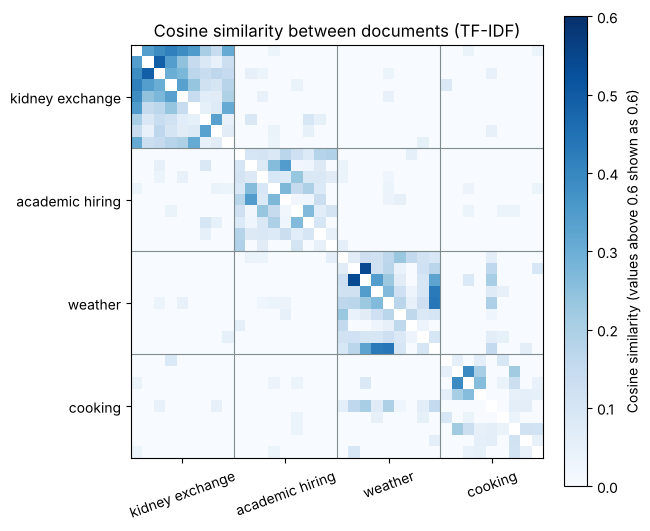

Average cosine, same topic:       0.132
Average cosine, different topics: 0.006


In [8]:
topic_index = np.array([TOPICS.index(t) for t in doc_topics])
same_topic = topic_index[:, None] == topic_index[None, :]
off_diagonal = ~np.eye(len(doc_ids), dtype=bool)
within = similarity[same_topic & off_diagonal].mean()
between = similarity[~same_topic].mean()

shown = similarity.copy()
np.fill_diagonal(shown, np.nan)
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(6.4, 5.4), constrained_layout=True)
image = ax.imshow(shown, cmap=cmap, vmin=0, vmax=0.6)
for boundary in (8.5, 17.5, 26.5):
    ax.axhline(boundary, color="#7F8C8D", linewidth=0.8)
    ax.axvline(boundary, color="#7F8C8D", linewidth=0.8)
centers = [4, 13, 22, 31]
ax.set_xticks(centers, TOPICS, rotation=20)
ax.set_yticks(centers, TOPICS)
ax.set_title("Cosine similarity between documents (TF-IDF)")
fig.colorbar(image, ax=ax, label="Cosine similarity (values above 0.6 shown as 0.6)")
plt.show()

print(f"Average cosine, same topic:       {within:.3f}")
print(f"Average cosine, different topics: {between:.3f}")

The four diagonal blocks are visibly darker: documents on the same topic share more weighted words. The cooking block is the lightest, because the cooking documents cover different dishes (bread, meat, sauces) and share fewer words. Most cells outside the blocks are close to zero, but not all: a few weather–cooking pairs, such as `W5` and `C5`, share words. The average cosine within a topic is many times the average between topics, yet it is still small, because short documents share only a few words even when they discuss the same topic.

**Compress the vectors with latent semantic analysis.** Our vectors have hundreds of entries, most of them zero. **Latent semantic analysis (LSA)** finds a few directions that capture the strongest patterns of words that occur together. It uses a truncated singular value decomposition (SVD) of the $n\times M$ TF-IDF matrix ($n=36$ documents, $M$ terms):

$$
X\approx U_r\,\Sigma_r\,V_r^\top ,
$$

where $r$ is the number of directions we keep, $\Sigma_r$ is an $r\times r$ diagonal matrix of the largest singular values, and the $r$ columns of the $M\times r$ matrix $V_r$ are the directions in term space. Each document's new coordinates are the rows of $U_r\Sigma_r=XV_r$: $r$ numbers instead of $M$. A term with a large positive or negative entry (its **loading**) in a column of $V_r$ is important for that direction.

`TruncatedSVD` computes this decomposition without first subtracting the column means, which keeps the matrix sparse. That is why the method is often used for TF-IDF matrices.

**Fit LSA with four directions.** The cell below prints the five terms with the largest absolute loadings for each direction and plots the documents in the new coordinates, colored by their true topic. The sign of each direction is arbitrary: flipping it changes nothing about the fit.

Direction  Terms with the largest absolute loadings
------------------------------------------------------------------------------
1          kidney (+0.50), donor (+0.42), patient (+0.39), type (+0.20), incompatible (+0.18)
2          air (+0.68), water (+0.25), vapor (+0.24), weather (+0.23), pressure (+0.23)
3          applicants (+0.40), faculty (+0.33), job (+0.23), offer (+0.19), department (+0.19)
4          dough (+0.46), bread (+0.40), gluten (+0.27), rises (+0.20), releases (+0.17)


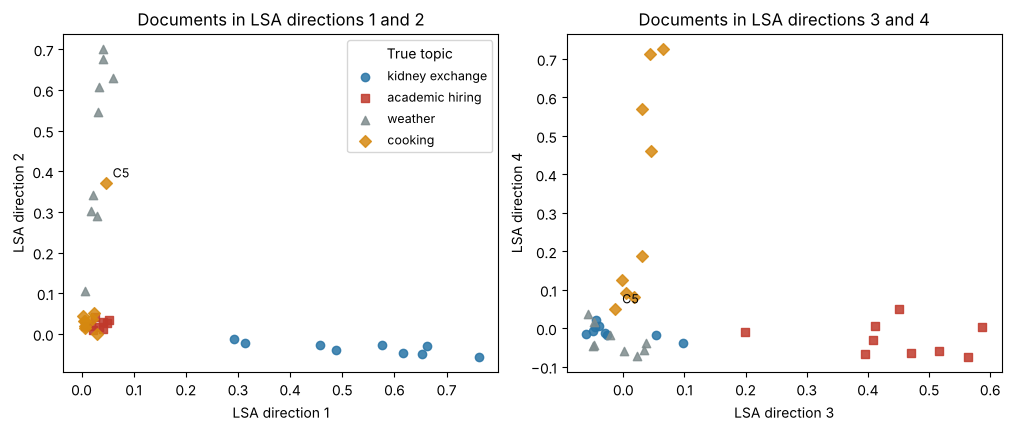

In [9]:
lsa = TruncatedSVD(n_components=4, random_state=SEED)
Z_lsa = lsa.fit_transform(X)          # document coordinates U_r Sigma_r, shape (36, 4)

print(f"{'Direction':<11}Terms with the largest absolute loadings")
print("-" * 78)
for c, loadings in enumerate(lsa.components_, start=1):
    top = np.argsort(-np.abs(loadings))[:5]
    print(f"{c:<11}" + ", ".join(f"{vocabulary[j]} ({loadings[j]:+.2f})" for j in top))

TOPIC_STYLE = {
    "kidney exchange": ("#2874A6", "o"),
    "academic hiring": ("#C0392B", "s"),
    "weather": ("#7F8C8D", "^"),
    "cooking": ("#D68910", "D"),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for topic, (color, marker) in TOPIC_STYLE.items():
        members = topic_index == TOPICS.index(topic)
        ax.scatter(Z_lsa[members, a], Z_lsa[members, b], color=color, marker=marker,
                   s=36, alpha=0.85, label=topic)
    c5 = doc_ids.index("C5")
    ax.annotate("C5", (Z_lsa[c5, a], Z_lsa[c5, b]), textcoords="offset points", xytext=(5, 4), fontsize=9)
    ax.set_xlabel(f"LSA direction {a + 1}")
    ax.set_ylabel(f"LSA direction {b + 1}")
    ax.set_title(f"Documents in LSA directions {a + 1} and {b + 1}")
axes[0].legend(title="True topic", fontsize=9)
plt.show()

Each direction is dominated by one topic's vocabulary: the printed terms show a kidney direction, a weather direction, an academic-hiring direction, and a cooking direction (the order is set by the singular values). No topic labels were used; the directions come only from which words occur together.

In the left panel, the kidney and weather documents move away from the origin along their own directions, while the hiring and cooking documents overlap near the origin. The right panel separates those two topics: the hiring documents spread along direction 3, and about half of the cooking documents (the bread and leavening ones: `C2`, `C3`, `C4`, `C7`) spread along direction 4, while the other cooking documents stay close to the origin. Two directions are not enough to separate four topics here. The cooking document `C5`, which talks about water, temperature, and air pressure, sits among the weather documents in the left panel.

**Group the documents with k-means.** **k-means** splits the documents into a chosen number of clusters and tries to minimize the total squared distance from each document to the mean (centroid) of its cluster. It alternates two steps: assign each document to the nearest centroid, then recompute each centroid. Each start reaches a local minimum, which depends on the starting centroids, so scikit-learn tries `n_init=10` starts and keeps the best one. (The "k" in the name counts clusters; it is not the $k$ of top-$k$ retrieval.)

Before clustering, we rescale each document's LSA coordinates to length 1. For unit vectors, $\lVert a-b\rVert^2=2-2\cos(a,b)$, so small distances correspond to large cosines, just as in Sections 1–2.

**Compare clusters with the true topics.** The cluster numbers are arbitrary labels: cluster 2 does not mean topic 2. We therefore use the **adjusted Rand index (ARI)**. It checks, for every pair of documents, whether the two groupings agree about putting the pair together or apart, and adjusts for the agreement expected by chance. ARI equals 1 when the clusters match the topics exactly (up to relabeling) and is near 0 for random clusters.

**Predict before running:** we cluster twice into 4 clusters: once using the four LSA coordinates and once using the full TF-IDF vectors. Which version will match the topics better?

The cell prints a table of true topic × cluster for each version, both ARIs, and the documents that land in a cluster dominated by another topic. Because k-means depends on its random starts, the last lines repeat both versions with ten different random seeds and report the range of ARIs.

In [10]:
N_COMPONENTS = 4     # LSA directions used for clustering
N_CLUSTERS = 4

Z = TruncatedSVD(n_components=N_COMPONENTS, random_state=SEED).fit_transform(X)
Z_unit = normalize(Z)   # each row has length 1
labels_lsa = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(Z_unit)
labels_raw = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(X)


def print_confusion(labels, title):
    print(title)
    print(f"{'True topic':<18}" + "".join(f"{'Cluster ' + str(c):>11}" for c in range(N_CLUSTERS)))
    for t, topic in enumerate(TOPICS):
        print(f"{topic:<18}" + "".join(f"{np.sum((topic_index == t) & (labels == c)):>11d}"
                                       for c in range(N_CLUSTERS)))


print_confusion(labels_lsa, f"K-MEANS ON {N_COMPONENTS} LSA COORDINATES")
print(f"Adjusted Rand index: {adjusted_rand_score(topic_index, labels_lsa):.3f}\n")
print_confusion(labels_raw, "K-MEANS ON FULL TF-IDF VECTORS")
print(f"Adjusted Rand index: {adjusted_rand_score(topic_index, labels_raw):.3f}")

print("\nLSA clusters: documents in a cluster dominated by another topic")
for c in range(N_CLUSTERS):
    members = np.flatnonzero(labels_lsa == c)
    majority = np.bincount(topic_index[members], minlength=len(TOPICS)).argmax()
    for i in members:
        if topic_index[i] != majority:
            print(f"  {doc_ids[i]} ({doc_topics[i]}) is in the {TOPICS[majority]} cluster: {doc_texts[i][:50]}...")

ari = {"LSA": [], "Full TF-IDF": []}
for seed in range(10):
    ari["LSA"].append(adjusted_rand_score(
        topic_index, KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=seed).fit_predict(Z_unit)))
    ari["Full TF-IDF"].append(adjusted_rand_score(
        topic_index, KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=seed).fit_predict(X)))
print(f"\n{'ARI over seeds 0-9':<20}{'Min':>8}{'Mean':>8}{'Max':>8}")
for name, values in ari.items():
    print(f"{name:<20}{min(values):>8.3f}{np.mean(values):>8.3f}{max(values):>8.3f}")

K-MEANS ON 4 LSA COORDINATES
True topic          Cluster 0  Cluster 1  Cluster 2  Cluster 3
kidney exchange             0          0          0          9
academic hiring             0          0          9          0
weather                     0          9          0          0
cooking                     8          1          0          0
Adjusted Rand index: 0.924

K-MEANS ON FULL TF-IDF VECTORS
True topic          Cluster 0  Cluster 1  Cluster 2  Cluster 3
kidney exchange             1          0          8          0
academic hiring             8          1          0          0
weather                     0          3          0          6
cooking                     8          0          0          1
Adjusted Rand index: 0.471

LSA clusters: documents in a cluster dominated by another topic
  C5 (cooking) is in the weather cluster: At high altitude, water boils at a lower temperatu...



ARI over seeds 0-9       Min    Mean     Max
LSA                    0.924   0.924   0.924
Full TF-IDF            0.670   0.791   0.857


With four LSA coordinates, k-means recovers the topics almost exactly: each cluster corresponds to one topic, and the only document in the "wrong" cluster is `C5`, the cooking document about air pressure, which joins the weather cluster. Given its words, that is a reasonable mistake. The ARI is close to 1.

On the full TF-IDF vectors, k-means does clearly worse with our seed: one cluster mixes the hiring and cooking documents, and the weather documents are split across two clusters. Over ten other seeds, its ARI changes from seed to seed and is always lower than the LSA version's, while the LSA result is the same for every seed. In the full space, most pairs of documents share no terms, so most distances between documents are close to $\sqrt{2}$ (cosine near 0) and k-means has little structure to work with; LSA keeps the few directions that carry the topic structure. These conclusions are for this small corpus; with other data, the number of directions and clusters must be chosen with care.

**Try it:** change `N_COMPONENTS` to 2 or 10 and rerun the cell. Before running, predict whether the ARI will go up or down, using the scatter plots above.

## 4 · Retrieval before answering

A language model answers from what its weights store and from the text in its prompt. **Retrieval-augmented generation (RAG)** adds a search step: retrieve the documents most similar to the question, place them in the prompt as evidence, and then let the model answer. In practice, the retriever is often a learned model rather than TF-IDF, and the corpus can be very large; the pipeline is the same.

**Build the prompts.** For each question $x$, let $D_k(x)$ be its top $k=3$ documents from Section 2. We build three prompts that end with `Answer:`:

| Prompt | Contents |
|---|---|
| (a) Question only | the question $x$ |
| (b) Retrieved evidence | the documents $D_k(x)$, then the question $x$ |
| (c) Unrelated evidence | the top 3 documents for a question from a **different topic**, then $x$ |

Prompt (c) is a **control**. It has the same format and the same number of documents as (b), but its evidence is about something else. If (b) helps and (c) does not, the help comes from the content of the evidence, not just from a longer prompt.

We also wrote a short correct answer $a$ for each question. The cell below prints prompt (b) for `Q2`, followed by the answer. Then, for every question, it lists the retrieved and the unrelated documents, how many of them are labeled relevant, and whether they contain the answer's words. A model can copy an answer from its evidence only if retrieval found it.

In [11]:
ANSWERS = {
    # Short correct answers; each starts with a space because it follows "Answer:".
    "Q1": " swap donors",
    "Q2": " an altruistic donor",
    "Q3": " limited time",
    "Q4": " a research talk",
    "Q5": " the dew point",
    "Q6": " stormy weather",
    "Q7": " carbon dioxide",
    "Q8": " lower air pressure",
}
K_EVIDENCE = 3


def retrieve(question, k=K_EVIDENCE):
    scores = (vectorizer.transform([question]) @ X.T).toarray()[0]
    return [doc_ids[j] for j in ranking(scores)[:k]]


def build_prompt(question, evidence_ids=()):
    lines = []
    if evidence_ids:
        lines.append("Evidence:")
        lines += [f"- {TEXT_BY_ID[d]}" for d in evidence_ids]
    lines += [f"Question: {question}", "Answer:"]
    return "\n".join(lines)


retrieved = {qid: retrieve(question) for qid, question, _ in QUESTIONS}
# Control: the evidence retrieved for the question four places later, which is about a different topic.
unrelated = {qid: retrieved[question_ids[(i + 4) % len(QUESTIONS)]] for i, qid in enumerate(question_ids)}


def contains_answer(evidence_ids, answer):
    return answer.strip().lower() in " ".join(TEXT_BY_ID[d] for d in evidence_ids).lower()


print("PROMPT (b) FOR Q2")
print("-" * 78)
print(build_prompt(QUESTIONS[1][1], retrieved["Q2"]) + ANSWERS["Q2"])
print("-" * 78)
print("(The model is scored on the answer tokens after 'Answer:'.)\n")

print(f"{'':<10}{'RETRIEVED EVIDENCE':<38}{'UNRELATED EVIDENCE'}")
print(f"{'Question':<10}{'Documents':<14}{'Relevant':>9}{'Has answer':>12}{'':<3}"
      f"{'Documents':<14}{'Relevant':>9}{'Has answer':>12}")
print("-" * 83)
for qid, question, relevant in QUESTIONS:
    columns = []
    for evidence in (retrieved[qid], unrelated[qid]):
        n_relevant = sum(d in relevant for d in evidence)
        found = "yes" if contains_answer(evidence, ANSWERS[qid]) else "no"
        columns.append(f"{', '.join(evidence):<14}{n_relevant:>7}/3{found:>12}")
    print(f"{qid:<10}{columns[0]}{'':<3}{columns[1]}")

PROMPT (b) FOR Q2
------------------------------------------------------------------------------
Evidence:
- An altruistic donor gives a kidney without naming a patient. Such a donor can start a chain of kidney transplants, in which each patient's paired donor gives a kidney to the next patient in the chain.
- A kidney exchange helps patients who have a willing living donor whose kidney is incompatible with them. Two incompatible patient-donor pairs can swap donors, so each patient receives a compatible kidney.
- Larger kidney exchange pools find more transplants because each incompatible patient-donor pair has more potential partners. Many programs combine pairs from several transplant centers into one pool.
Question: What kind of donor can start a chain of kidney transplants?
Answer: an altruistic donor
------------------------------------------------------------------------------
(The model is scored on the answer tokens after 'Answer:'.)

          RETRIEVED EVIDENCE               

For every question, the retrieved evidence includes at least one relevant document and contains the words of the short answer, so a model that reads its prompt has the information it needs. The unrelated evidence contains no relevant document and never contains the answer. Retrieval quality limits what this step can do: had retrieval missed the answer, the evidence could not help.

Next, we measure whether the evidence actually changes a language model's predictions. As in Week 1, we do this without generating text: we compute the log-probability the model assigns to the correct answer's tokens.

## 5 · Scoring answers with DistilGPT2

We now return to the pretrained **DistilGPT2** model from Weeks 1–3. This is the only section that uses the Transformers library and downloads a model, so run it with an internet connection (for example, in Colab). The download is the same as in Weeks 1–3.

**Install the Transformers versions used in Weeks 1–3.** The cell below is Week 1's setup cell. PyTorch is already installed by now, so it installs only the three pinned libraries.

In [12]:
# Setup for Section 5: the same library versions as Weeks 1-3
import importlib.util, subprocess, sys
packages = ["transformers==4.57.6", "huggingface-hub==0.36.2", "tokenizers==0.22.2"]
if importlib.util.find_spec("torch") is None:
    packages.append("torch==2.8.0")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
print("Setup complete.")

Setup complete.


**Load the tokenizer and pretrained model.** This cell is Week 1's loading code: the same checkpoint (`MODEL_ID`) at the same pinned version (`REVISION`), with the end-of-sequence token used for padding. It should report about 82 million parameters, as in Week 1. Loading does not train the model.

In [ ]:
# DistilGPT2: downloads the model, exactly as in Week 1.
import os, random, time
import torch
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 425
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

MODEL_ID = "distilbert/distilgpt2"
REVISION = "2290a62682d06624634c1f46a6ad5be0f47f38aa"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, use_safetensors=True
).to(device)
# GPT-2 has no dedicated PAD token. Mask padding by position, not by token ID.
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
model.config.pad_token_id = tokenizer.pad_token_id
model.eval()
print("Device:", device, "| torch:", torch.__version__, "| transformers:", transformers.__version__)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Loaded pretrained weights; no optimizer step has run.")

**Score the answer with Week 1's method.** Write the answer's tokens as $a_1,\ldots,a_T$. Given a prompt (a context), the model assigns the answer the log-probability

$$
\ln p(a\mid \text{prompt})=\sum_{t=1}^{T}\ln p(a_t\mid \text{prompt},a_{<t}),
$$

the same sum of next-token log-probabilities we computed for a sentence in Week 1. Here we score only the answer tokens; the prompt is context. The **evidence gain** for question $x$ is

$$
\Delta(x)=\ln p\big(a\mid D_k(x),x\big)-\ln p(a\mid x).
$$

Because $\Delta$ is a difference of logs, $e^{\Delta}$ is the factor by which the evidence multiplies the answer's probability: $\Delta=0$ means no change, and $\Delta>0$ means the evidence made the correct answer more likely. We compute the same gain for the unrelated evidence (control).

**What the code does.** For each question, the cell joins the prompt's token IDs and the answer's token IDs, runs the model once, and adds the log-probabilities of the answer tokens, each predicted from the position just before it (as in Week 1). It first prints a token-by-token table for `Q5` under prompts (a) and (b), then a summary for all eight questions. No weights change.

**Predict before running:** for how many of the eight questions will the retrieved evidence raise the answer's log-probability? Will the unrelated evidence raise it too?

<details><summary>Why we can join the token IDs</summary>

Each answer starts with a space and each prompt ends with `Answer:`. GPT-2's tokenizer first splits text into pieces: each leading space stays attached to the word that follows it, and punctuation such as `:` forms a separate piece. Its merges never cross these pieces. Because the prompt ends with `:` and each answer starts with a space, tokenizing the prompt and the answer separately gives the same tokens as tokenizing the joined text. The prompt length is well within DistilGPT2's limit of 1,024 tokens.

</details>

In [ ]:
@torch.no_grad()
def answer_token_log_probs(prompt, answer):
    # Week 1's scoring: position t predicts token t + 1, so each answer token is scored by
    # the log-probabilities at the position just before it.
    prompt_ids = tokenizer.encode(prompt, add_special_tokens=False)
    answer_ids = tokenizer.encode(answer, add_special_tokens=False)
    ids = prompt_ids + answer_ids
    log_probs = model(input_ids=torch.tensor([ids], device=device)).logits[0, :-1].log_softmax(dim=-1)
    return [(tokenizer.decode([ids[position]]), log_probs[position - 1, ids[position]].item())
            for position in range(len(prompt_ids), len(ids))]


def answer_log_prob(prompt, answer):
    return sum(log_p for _, log_p in answer_token_log_probs(prompt, answer))


qid, question, _ = QUESTIONS[question_ids.index("Q5")]
print(f"{qid}: {question} | answer: {ANSWERS[qid]!r}")
print(f"{'Answer token':<14}{'p, question only':>18}{'p, with evidence':>18}")
alone = answer_token_log_probs(build_prompt(question), ANSWERS[qid])
with_evidence = answer_token_log_probs(build_prompt(question, retrieved[qid]), ANSWERS[qid])
for (token, log_p_alone), (_, log_p_evidence) in zip(alone, with_evidence):
    print(f"{token!r:<14}{math.exp(log_p_alone):>18.6f}{math.exp(log_p_evidence):>18.6f}")
print(f"{'Sum of ln p':<14}{sum(v for _, v in alone):>18.3f}{sum(v for _, v in with_evidence):>18.3f}")

print("\n" + "=" * 86)
print(f"{'Question':<10}{'Answer':<22}{'(a) alone':>11}{'(b) retrieved':>15}{'(c) unrelated':>15}"
      f"{'Gain (b)':>10}{'Gain (c)':>10}")
print("-" * 86)
results = []
for qid, question, _ in QUESTIONS:
    answer = ANSWERS[qid]
    alone = answer_log_prob(build_prompt(question), answer)
    with_retrieved = answer_log_prob(build_prompt(question, retrieved[qid]), answer)
    with_unrelated = answer_log_prob(build_prompt(question, unrelated[qid]), answer)
    results.append((alone, with_retrieved, with_unrelated))
    print(f"{qid:<10}{answer!r:<22}{alone:>11.3f}{with_retrieved:>15.3f}{with_unrelated:>15.3f}"
          f"{with_retrieved - alone:>10.3f}{with_unrelated - alone:>10.3f}")
results = np.array(results)
gain_retrieved = results[:, 1] - results[:, 0]
gain_unrelated = results[:, 2] - results[:, 0]
print("-" * 86)
print(f"{'Mean':<32}{results[:, 0].mean():>11.3f}{results[:, 1].mean():>15.3f}{results[:, 2].mean():>15.3f}"
      f"{gain_retrieved.mean():>10.3f}{gain_unrelated.mean():>10.3f}")
print(f"\nRetrieved evidence raised ln p(answer) for {np.sum(gain_retrieved > 0)} of {len(QUESTIONS)} questions.")
print(f"Unrelated evidence raised ln p(answer) for {np.sum(gain_unrelated > 0)} of {len(QUESTIONS)} questions.")

**What to look for:**

- **Column (b) versus column (a).** A positive gain means the retrieved evidence made the correct answer more likely. Read the size on the probability scale: a gain of 2 nats multiplies the answer's probability by $e^2\approx7.4$.
- **Gain (b) versus gain (c).** The control separates the content of the evidence from the longer prompt. If relevant evidence helps, gain (b) should be clearly larger than gain (c) for most questions. If both gains are similar, the change comes mostly from the prompt's length or format.
- **The token table for `Q5`.** Check which answer tokens change most. Later tokens of an answer are predicted with the earlier answer tokens already in the context, so they can be likely even without evidence (for example, ` point` after ` dew`).
- **How much to conclude.** DistilGPT2 is a small model trained to continue text, not to answer questions (Week 1). If it benefits from evidence, it may do so partly by copying words that appear in its prompt, which is still useful. With only eight questions, treat any pattern as suggestive rather than as an estimate for other questions or models.

**Optional: use DistilGPT2's hidden states as document vectors.** TF-IDF missed the connection between `noodles` and `pasta` in `Q8`. A language model represents each token by a vector (a **hidden state**) that depends on the surrounding text, so related words may receive nearby vectors. To get one vector per document, we average the final-layer hidden states over the document's tokens (**mean pooling**), ignoring padding positions.

Before comparing vectors, we subtract the average document vector (**centering**). Hidden states of GPT-2-style models can share a large common component, which would make every pair of documents look similar. We then rank documents by cosine similarity and compute P@1 and P@3 with the same function as in Section 2.

In [ ]:
@torch.no_grad()
def mean_pooled_embeddings(texts, batch_size=12):
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(texts[start:start + batch_size], return_tensors="pt", padding=True).to(device)
        hidden = model(**batch, output_hidden_states=True).hidden_states[-1]   # final layer
        mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)         # 1 for real tokens
        vectors.append(((hidden * mask).sum(dim=1) / mask.sum(dim=1)).cpu().numpy())
    return np.concatenate(vectors)


doc_embeddings = mean_pooled_embeddings(doc_texts)
question_embeddings = mean_pooled_embeddings(question_texts)
center = doc_embeddings.mean(axis=0)
embedding_scores = normalize(question_embeddings - center) @ normalize(doc_embeddings - center).T

emb_p_at_1 = precision_at_k(embedding_scores, 1)
emb_p_at_3 = precision_at_k(embedding_scores, 3)
print(f"Embedding size: {doc_embeddings.shape[1]}")
print(f"{'Question':<10}{'TF-IDF P@1':>11}{'P@3':>7}{'Hidden states P@1':>19}{'P@3':>7}   Top 3 (hidden states)")
print("-" * 86)
for i, (qid, _, relevant) in enumerate(QUESTIONS):
    top = [doc_ids[j] + ("*" if doc_ids[j] in relevant else "") for j in ranking(embedding_scores[i])[:3]]
    print(f"{qid:<10}{p_at_1[i]:>11.2f}{p_at_3[i]:>7.2f}{emb_p_at_1[i]:>19.2f}{emb_p_at_3[i]:>7.2f}   {', '.join(top)}")
print("-" * 86)
print(f"{'Mean':<10}{p_at_1.mean():>11.3f}{p_at_3.mean():>7.3f}{emb_p_at_1.mean():>19.3f}{emb_p_at_3.mean():>7.3f}")

**What to look for:** compare the mean P@1 and P@3 of the two methods, then look at `Q8`, whose wording differs from its relevant documents. DistilGPT2 was trained to predict the next token, not to place a question near the documents that answer it, so averaged hidden states may or may not beat TF-IDF on this small corpus. Practical retrieval systems often use encoders trained for exactly this purpose; the original RAG system, for example, uses a dense retriever whose encoders were trained on question–passage pairs.

## Recap

We followed a question from a corpus of documents to a scored answer:

**Documents → TF-IDF vectors → cosine similarity → retrieved evidence → evidence + question → answer log-probability**

TF-IDF turns each document into a vector that weights words frequent in the document and rare in the corpus. Cosine similarity ranks documents for a query, and precision@k measures how many of the top documents are relevant. The same similarities reveal topics: LSA compresses the vectors into a few directions, and k-means on those directions recovered our four topics almost exactly. Finally, retrieved documents become evidence in a prompt, and Week 1's log-probabilities measure whether that evidence makes a correct answer more likely.

### Check your understanding

1. A word appears in all 36 documents. What is its idf under the formula we used, and why is it not zero?
2. A query contains only words that are not in the vocabulary. What is its TF-IDF vector, and what does the ranking look like?
3. Why do we compare the k-means clusters with the true topics using the adjusted Rand index instead of the fraction of documents whose cluster number equals their topic number?
4. Retrieved evidence raises an answer's log-probability by 2 nats. By what factor did the answer's probability change?
5. Why did we also score each answer after unrelated evidence?

<details><summary>Answers · open after discussing</summary>

1. With $n=36$ and $\mathrm{df}=36$, $\mathrm{idf}=\ln(37/37)+1=1$, the smallest possible value. The "+1" outside the logarithm keeps the word from being dropped entirely; it still receives the lowest weight per occurrence.
2. Every entry is zero, so its dot product with every document is 0. All documents tie, and the ranking is arbitrary: the search has no information to use.
3. Cluster numbers are arbitrary labels; the same grouping could number its clusters in any order. The ARI compares which pairs of documents are grouped together, so it does not depend on the numbering, and it adjusts for agreement expected by chance.
4. It multiplied the probability by $e^{2}\approx7.4$, because $\ln p_{\text{new}}-\ln p_{\text{old}}=2$ means $p_{\text{new}}/p_{\text{old}}=e^{2}$.
5. Adding evidence also makes the prompt longer and changes its format. Unrelated evidence with the same number of documents and the same format is a control: an effect that appears with retrieved evidence but not with unrelated evidence can be attributed to the evidence's content.

</details>

### Next week: putting it all together

Next week, we review the whole sequence through one task, end to end. Starting from Week 6's noisy "Which number is largest?" task, we give a policy a supervised start, train it with rewards that score both its answers and its reported confidence, and finish by answering with a coverage guarantee. Each step reuses an idea from an earlier week in a few lines of code.

## References and further reading

- [scikit-learn: TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html): TF-IDF features, including the smoothed idf formula used here.
- [scikit-learn: TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html): latent semantic analysis.
- [Lewis et al. (2020): Retrieval-augmented generation for knowledge-intensive NLP tasks](https://arxiv.org/abs/2005.11401): retrieval before generation.
- [DistilGPT2 model card](https://huggingface.co/distilbert/distilgpt2): the pretrained model used in Weeks 1–3 and here.